# Generate results and figures
For fmrs/1_two_peak_simulation

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import re
import pandas as pd

## Load the data from the variable lw/eps data

In [4]:

name_parts = re.compile(r'(\w+)_(\d\.\d+)_(\de\-0\d)_(\d\.\d)')
sim_res = Path('sim_results')
type = []
sep = []
nv = []
delta = []
all_df = []
for fp in sim_res.glob('*.csv'):
    type.append(name_parts.search(fp.stem)[1])
    sep.append(float(name_parts.search(fp.stem)[2]))
    nv.append(float(name_parts.search(fp.stem)[3]))
    delta.append(float(name_parts.search(fp.stem)[4]))
    all_df.append(pd.read_csv(fp, index_col=0))

mi = pd.MultiIndex.from_arrays([type, sep, nv])
full_sim_data = pd.concat(all_df, keys=mi)

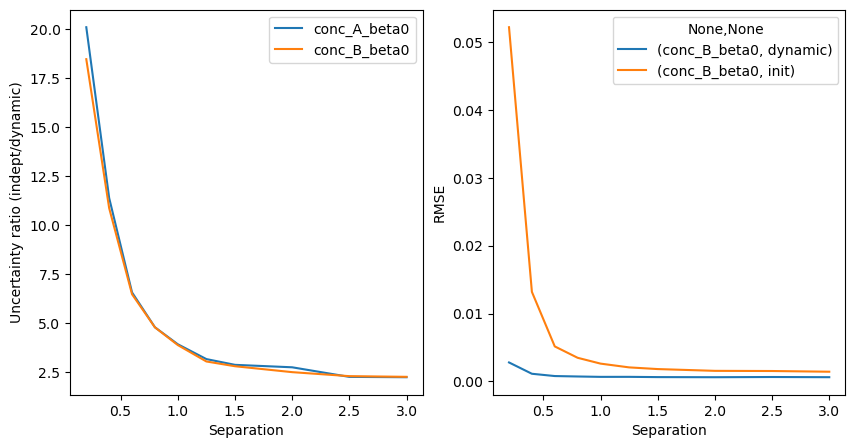

In [27]:
# Parameter from simulation to calculate RMSE
simulation_delta = 0.2  # The delta that peak B increases by
fid_scaling = 1.1873  # The automatic internal scaling factor applied by FSL-MRS (scaled by norm of FID)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
ratio = full_sim_data.groupby(level=[0,1,2]).std().loc['init']\
    / full_sim_data.groupby(level=[0,1,2]).std().loc['dynamic']
ratio_sep = ratio.groupby(level=0).mean()

# Plot the ratio of std as a function of peak separation
ratio_sep[['conc_A_beta0','conc_B_beta0']].plot(ax=ax1)

# Plot the 
rmse = (full_sim_data.filter(like='conc_B_beta0')/fid_scaling - simulation_delta)\
    .pow(2)\
    .groupby(level=[0,1,2])\
    .mean()\
    .pow(0.5)

rmse.groupby(level=[0,1]).mean().unstack(level=0).plot(ax=ax2)

ax1.set_xlabel('Separation')
ax2.set_xlabel('Separation')

ax1.set_ylabel('Uncertainty ratio (indept/dynamic)')
ax2.set_ylabel('RMSE')

plt.show()

In [7]:
from pathlib import Path
import re
import pandas as pd
name_parts = re.compile(r'(\w+)_(\d\.\d+)_(\de\-0\d)_(\d\.\d)')
sim_res = Path('sim_results_linked')
type = []
sep = []
nv = []
delta = []
all_df = []
for fp in sim_res.glob('*.csv'):
    type.append(name_parts.search(fp.stem)[1])
    sep.append(float(name_parts.search(fp.stem)[2]))
    nv.append(float(name_parts.search(fp.stem)[3]))
    delta.append(float(name_parts.search(fp.stem)[4]))
    all_df.append(pd.read_csv(fp, index_col=0))

mi = pd.MultiIndex.from_arrays([type, sep, nv])
full_sim_data_linked = pd.concat(all_df, keys=mi)

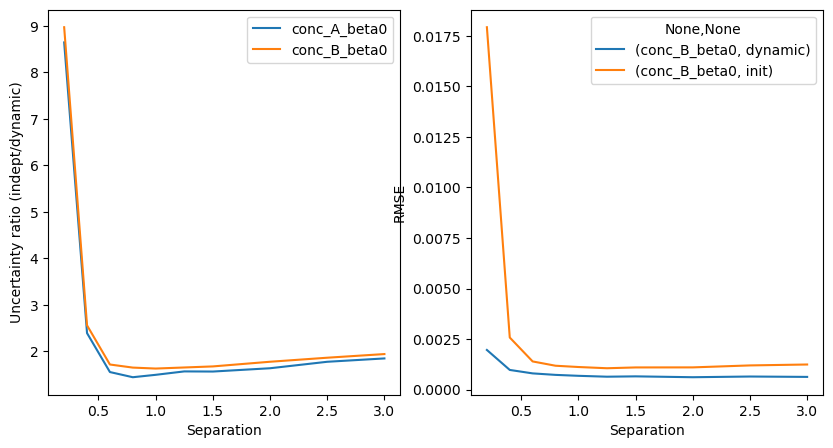

In [28]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

ratio_linked = full_sim_data_linked.groupby(level=[0,1,2]).std().loc['init']\
    / full_sim_data_linked.groupby(level=[0,1,2]).std().loc['dynamic']
ratio_sep_linked = ratio_linked.groupby(level=0).mean()
ratio_sep_linked[['conc_A_beta0','conc_B_beta0']].plot(ax=ax1)

rmse_linked = (full_sim_data_linked.filter(like='conc_B_beta0')/fid_scaling - simulation_delta).pow(2).groupby(level=[0,1,2]).mean().pow(0.5)
rmse_linked.groupby(level=[0,1]).mean().unstack(level=0).plot(ax=ax2)

ax1.set_xlabel('Separation')
ax2.set_xlabel('Separation')

ax1.set_ylabel('Uncertainty ratio (indept/dynamic)')
ax2.set_ylabel('RMSE')

plt.show()

0.20    18.463960
0.40    10.856778
0.60     6.459199
0.80     4.769040
1.00     3.864478
1.25     3.025490
1.50     2.782678
2.00     2.480664
2.50     2.276122
3.00     2.241648
Name: conc_B_beta0, dtype: float64

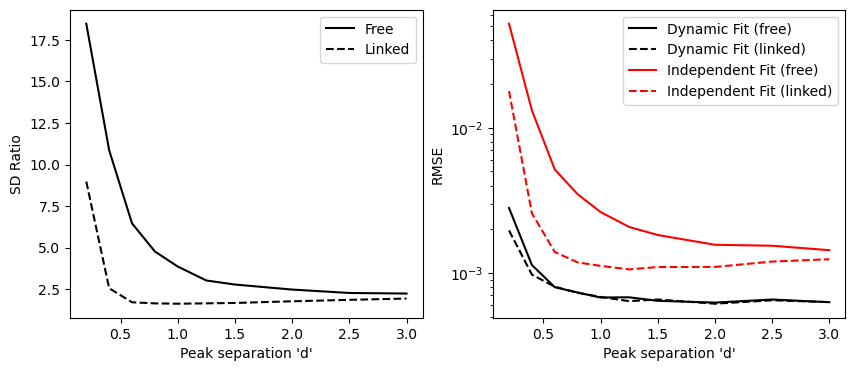

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].plot(ratio_sep.conc_B_beta0, 'k', label='Free')
axes[0].plot(ratio_sep_linked.conc_B_beta0, 'k--', label='Linked')
axes[0].legend()
axes[0].set_xlabel("Peak separation 'd'")
axes[0].set_ylabel("SD Ratio")

df1 = rmse.groupby(level=[0,1]).mean().unstack(level=0)
df2 = rmse_linked.groupby(level=[0,1]).mean().unstack(level=0)
axes[1].semilogy(df1.index.to_list(), df1.conc_B_beta0.dynamic.to_list(),'k', label='Dynamic Fit (free)')
axes[1].semilogy(df2.index.to_list(), df2.conc_B_beta0.dynamic.to_list(),'k--', label='Dynamic Fit (linked)')
axes[1].semilogy(df1.index.to_list(), df1.conc_B_beta0.init.to_list(), 'r', label='Independent Fit (free)')
axes[1].semilogy(df2.index.to_list(), df2.conc_B_beta0.init.to_list(),'r--', label='Independent Fit (linked)')
axes[1].legend()
axes[1].set_xlabel("Peak separation 'd'")
axes[1].set_ylabel("RMSE")

plt.savefig('../../publication/figures/fig3ab_fmrs_tal.png', dpi=400, bbox_inches='tight', transparent=True)